In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [10]:
PROJECT_ROOT = r"D:\AI-Powered-Diabetic-Retinopathy-System"

CSV_PATH = os.path.join(
    PROJECT_ROOT,
    "ml-model",
    "dataset",
    "raw",
    "train.csv"
)

IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "ml-model",
    "dataset",
    "raw",
    "train_images"
)

MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "ml-model",
    "saved_models",
    "best_resnet50.keras"
)

IMAGE_SIZE = (224, 224)

CLASS_NAMES = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

NUM_CLASSES = 5

In [3]:
df = pd.read_csv(CSV_PATH)

# Create image paths
df["image_path"] = df["id_code"].apply(
    lambda x: os.path.join(IMAGE_DIR, x + ".png")
)

# Keep only valid images
df = df[df["image_path"].apply(os.path.exists)].copy()

print("Total valid images:", len(df))

Total valid images: 3662


In [11]:
# First split: 85% train+validation, 15% test

train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["diagnosis"],
    random_state=42
)

# Second split:
# 15% of the complete dataset becomes validation
validation_fraction = 0.15 / 0.85

train_df, val_df = train_test_split(
    train_val_df,
    test_size=validation_fraction,
    stratify=train_val_df["diagnosis"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 2562
Validation: 550
Test: 550


In [13]:
print("\nTest-set class distribution:")
print(test_df["diagnosis"].value_counts().sort_index())


Test-set class distribution:
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


In [12]:
model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")
print(model.name)

Model loaded successfully.
ResNet50_DR_Classifier


In [14]:
base_model = model.get_layer("resnet50")

last_conv_layer = base_model.get_layer(
    "conv5_block3_out"
)

print("Target layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

Target layer: conv5_block3_out
Output shape: (None, 7, 7, 2048)


In [15]:
feature_model = tf.keras.models.Model(
    inputs=base_model.input,
    outputs=last_conv_layer.output
)

gap_layer = model.get_layer(
    "global_average_pooling"
)

dropout_layer = model.get_layer(
    "dropout"
)

classifier_layer = model.get_layer(
    "dr_severity"
)

In [16]:
def generate_gradcam(image_path):

    # -----------------------------------------------------
    # Load image
    # -----------------------------------------------------

    image_bytes = tf.io.read_file(image_path)

    image = tf.image.decode_png(
        image_bytes,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    input_tensor = tf.expand_dims(
        image,
        axis=0
    )

    # -----------------------------------------------------
    # Calculate feature maps and gradients
    # -----------------------------------------------------

    with tf.GradientTape() as tape:

        feature_maps = feature_model(
            input_tensor,
            training=False
        )

        pooled_features = gap_layer(
            feature_maps
        )

        dropped_features = dropout_layer(
            pooled_features,
            training=False
        )

        predictions = classifier_layer(
            dropped_features
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_score = predictions[
            0,
            predicted_class
        ]

    # -----------------------------------------------------
    # Gradients of predicted class
    # -----------------------------------------------------

    gradients = tape.gradient(
        class_score,
        feature_maps
    )

    # -----------------------------------------------------
    # Global average pooling of gradients
    # -----------------------------------------------------

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # -----------------------------------------------------
    # Weight feature maps
    # -----------------------------------------------------

    feature_maps = feature_maps[0]

    heatmap = tf.reduce_sum(
        feature_maps * pooled_gradients,
        axis=-1
    )

    # -----------------------------------------------------
    # ReLU
    # -----------------------------------------------------

    heatmap = tf.maximum(
        heatmap,
        0
    )

    # -----------------------------------------------------
    # Normalize
    # -----------------------------------------------------

    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:
        heatmap = heatmap / max_value

    heatmap = heatmap.numpy()

    # -----------------------------------------------------
    # Convert image for visualization
    # -----------------------------------------------------

    original_image = image.numpy().astype(
        np.uint8
    )

    # -----------------------------------------------------
    # Resize heatmap
    # -----------------------------------------------------

    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224)
    )

    # -----------------------------------------------------
    # Convert heatmap to color
    # -----------------------------------------------------

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # OpenCV BGR → RGB
    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # -----------------------------------------------------
    # Create overlay
    # -----------------------------------------------------

    overlay = cv2.addWeighted(
        original_image,
        0.55,
        heatmap_color,
        0.45,
        0
    )

    # -----------------------------------------------------
    # Prediction information
    # -----------------------------------------------------

    probabilities = predictions[
        0
    ].numpy()

    predicted_class = int(
        predicted_class.numpy()
    )

    confidence = float(
        probabilities[predicted_class]
    )

    return {
        "original": original_image,
        "heatmap": heatmap_resized,
        "overlay": overlay,
        "predicted_class": predicted_class,
        "confidence": confidence,
        "probabilities": probabilities
    }

In [18]:
def predict_single_image(image_path):

    image_bytes = tf.io.read_file(
        image_path
    )

    image = tf.image.decode_png(
        image_bytes,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.expand_dims(
        image,
        axis=0
    )

    prediction = model.predict(
        image,
        verbose=0
    )[0]

    predicted_class = int(
        np.argmax(prediction)
    )

    confidence = float(
        prediction[predicted_class]
    )

    return predicted_class, confidence, prediction

In [19]:
selected_images = {}

for class_id in range(NUM_CLASSES):

    class_candidates = []

    # Get test images belonging to this class
    class_test_df = test_df[
        test_df["diagnosis"] == class_id
    ]

    for _, row in class_test_df.iterrows():

        image_path = row["image_path"]

        predicted_class, confidence, probabilities = \
            predict_single_image(image_path)

        # Only keep correctly classified images
        if predicted_class == class_id:

            class_candidates.append({
                "image_path": image_path,
                "true_class": class_id,
                "predicted_class": predicted_class,
                "confidence": confidence
            })

    # -----------------------------------------------------
    # Select highest-confidence correct prediction
    # -----------------------------------------------------

    if class_candidates:

        class_candidates = sorted(
            class_candidates,
            key=lambda x: x["confidence"],
            reverse=True
        )

        selected_images[class_id] = \
            class_candidates[0]

        print(
            f"{CLASS_NAMES[class_id]} → "
            f"selected with confidence "
            f"{class_candidates[0]['confidence'] * 100:.2f}%"
        )

    else:

        print(
            f"WARNING: No correctly classified "
            f"image found for {CLASS_NAMES[class_id]}"
        )

No DR → selected with confidence 99.89%
Mild DR → selected with confidence 93.69%
Moderate DR → selected with confidence 92.20%
Severe DR → selected with confidence 87.97%
Proliferative DR → selected with confidence 88.05%


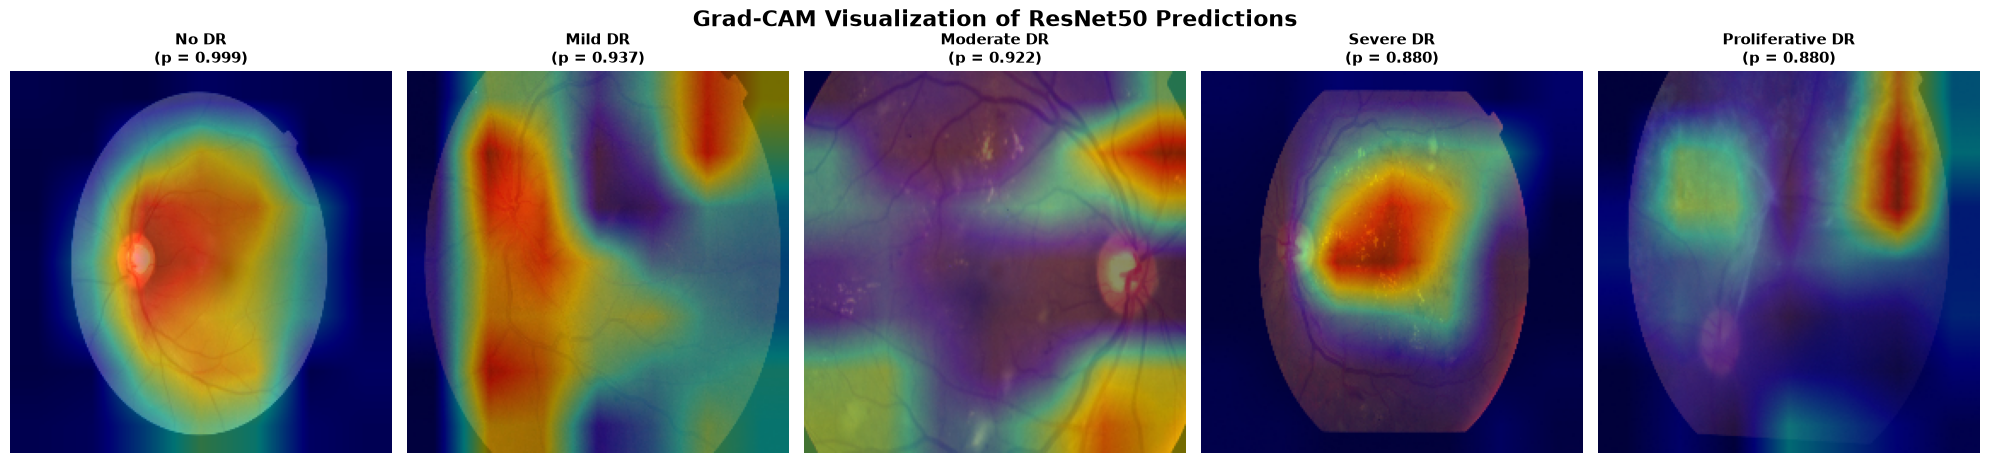

In [20]:
fig, axes = plt.subplots(
    1,
    5,
    figsize=(20, 4.5)
)

for class_id in range(NUM_CLASSES):

    ax = axes[class_id]

    if class_id not in selected_images:

        ax.axis("off")

        ax.set_title(
            f"{CLASS_NAMES[class_id]}\nNo correct sample",
            fontsize=10
        )

        continue

    image_info = selected_images[class_id]

    result = generate_gradcam(
        image_info["image_path"]
    )

    confidence = result["confidence"]

    # Display Grad-CAM overlay
    ax.imshow(
        result["overlay"]
    )

    ax.axis("off")

    ax.set_title(
        f"{CLASS_NAMES[class_id]}\n"
        f"(p = {confidence:.3f})",
        fontsize=11,
        fontweight="bold"
    )

plt.suptitle(
    "Grad-CAM Visualization of ResNet50 Predictions",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "gradcam_five_severity_levels.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()